**Barbados, June 2026: Article IV and a new Stand-By Arrangement**

IMF Country Report No. 26/155, read with Gemini Flash models and checked against the report's own tables.

**1. System tools.** Adds poppler for reading the PDF, and the Python libraries Colab lacks. *Saved as nothing; this only prepares the runtime.*

In [1]:
!apt-get -qq install -y poppler-utils > /dev/null
%pip install -q blinker==1.9.0 python-box==8.0.0 dacite==1.9.2 retrying==1.4.2 semantic-text-splitter==0.33.1 faiss-cpu==1.15.1

**2. Settings and the bus.** Settings are JSON read into a Box. Publishing a result on the bus also saves it and logs it. *Saved as files in `results/`.*

In [2]:
import base64, enum, hashlib, json, os, re, subprocess, tempfile, textwrap, time, typing
from dataclasses import dataclass, fields, is_dataclass
from pathlib import Path
from typing import Literal, Optional

import dacite
import faiss
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from blinker import signal
from box import Box
from retrying import retry
from semantic_text_splitter import TextSplitter
from sentence_transformers import SentenceTransformer
from tokenizers import Tokenizer

OPTIONS = Box(json.loads("""{
  "source": {"pdf": "data/IMF_CR_26_155_Barbados_2026_Article_IV.pdf", "country": "Barbados", "projection_year": 2026},
  "models": {"drafter": "gemini-3.5-flash", "reviewer": "gemini-3.6-flash", "secret": "GEMINI_FREE_KEY", "tokens": 16384},
  "retrieval": {"encoder": "sentence-transformers/multi-qa-MiniLM-L6-cos-v1", "floor": 250, "ceiling": 400, "shared": 50, "neighbours": 6},
  "limits": {"words": 100, "picture_chars": 400, "tag_group": 20},
  "paths": {"replies": "cache/replies.parquet", "out": "results"}
}"""))
for folder in (Path(OPTIONS.paths.out), Path(OPTIONS.paths.replies).parent):
    folder.mkdir(exist_ok=True)

published = signal("published")
DESK, JOURNAL = {}, []


def to_plain(thing):
    if isinstance(thing, pd.DataFrame):
        return json.loads(thing.to_json(orient="records"))
    if isinstance(thing, np.generic):
        return thing.item()
    raise TypeError(type(thing))


@published.connect
def store_on_desk(name, value):
    DESK[name] = value


@published.connect
def write_json(name, value):
    if not name.startswith("_"):
        Path(OPTIONS.paths.out, f"{name}.json").write_text(json.dumps(value, indent=1, default=to_plain), encoding="utf-8")


@published.connect
def note_in_journal(name, value):
    JOURNAL.append({"result": name, "at": time.strftime("%H:%M:%S"), "kind": type(value).__name__, "size": len(value) if hasattr(value, "__len__") else 1})


def publish(name, value):
    """Announce a finished result. The three listeners above keep, save and log it."""
    published.send(name, value=value)
    return value

**3. Reply classes.** Each model reply is a dataclass read with dacite, and the same class produces the JSON schema sent to Gemini. *Saved as nothing.*

In [3]:
THEME_NAMES = ("Inflation & Prices", "Interest Rates & Credit", "Housing & Real Estate", "Banking Capital & Liquidity", "Sovereign Debt", "Labor Market Dynamics", "Systemic Financial Risk")
Theme = Literal["Inflation & Prices", "Interest Rates & Credit", "Housing & Real Estate", "Banking Capital & Liquidity", "Sovereign Debt", "Labor Market Dynamics", "Systemic Financial Risk", "none"]
Outcome = Literal["CORRECT", "WRONG", "NOT_FOUND", "CORRECTLY_NULL", "MISSED"]


@dataclass
class Transcript:
    table_text: str


@dataclass
class Digest:
    paragraph: str


@dataclass
class Grades:
    consistency: int
    completeness: int
    factual_alignment: int
    problems: list[str]


@dataclass
class Finding:
    section: str
    sentence: str


@dataclass
class Briefing:
    findings: list[Finding]


@dataclass
class Ruling:
    item: int
    holds: bool
    why: str


@dataclass
class Rulings:
    results: list[Ruling]


@dataclass
class Restated:
    meanings: list[str]


@dataclass
class Label:
    passage: str
    theme: Theme


@dataclass
class Labels:
    labels: list[Label]


@dataclass
class Evidence:
    title: str
    meaning: str
    page: int
    words: str


@dataclass
class Balance:
    strengths: list[Evidence]
    vulnerabilities: list[Evidence]


@dataclass
class Datum:
    value: Optional[float]
    period: Optional[str]
    page: Optional[int]
    source_text: Optional[str]
    why_missing: Optional[str]


@dataclass
class Record:
    gdp_growth_forecast_pct: Datum
    headline_inflation_rate_pct: Datum
    central_bank_policy_rate_pct: Datum
    non_performing_loan_ratio: Datum
    unemployment_rate_pct: Datum
    tier_1_capital_ratio: Datum


@dataclass
class Check:
    indicator: str
    outcome: Outcome
    seen_value: Optional[float]
    comment: str


@dataclass
class AuditSheet:
    checks: list[Check]


@dataclass
class Chosen:
    row: str
    reason: str


@dataclass
class Selection:
    rows: list[Chosen]


@dataclass
class Response:
    answer: str
    passages_used: list[str]
    report_has_answer: bool


@dataclass
class AnswerGrades:
    faithfulness: int
    completeness: int
    note: str


INDICATORS = [f.name for f in fields(Record)]
ATOMS = {str: "string", int: "integer", float: "number", bool: "boolean"}


def schema_for(kind):
    """Build a JSON schema from a dataclass or type hint."""
    origin, args = typing.get_origin(kind), typing.get_args(kind)
    if is_dataclass(kind):
        hints = typing.get_type_hints(kind)
        return {"type": "object", "properties": {n: schema_for(t) for n, t in hints.items()}, "required": list(hints)}
    if origin is list:
        return {"type": "array", "items": schema_for(args[0])}
    if origin is Literal:
        return {"type": "string", "enum": list(args)}
    if origin is typing.Union:
        return {"anyOf": [schema_for(args[0]), {"type": "null"}]}
    return {"type": ATOMS[kind]}

**4. Prompts.** One Enum member per job: its system instruction and its message. *Saved as `results/prompt_book.json` at the end.*

In [4]:
class Ask(enum.Enum):
    READ_TABLE = ("You transcribe tables from page images of IMF reports. Copy every label and number exactly, one table row per line, values separated by single spaces. Write ... for an empty cell.",
                  "Transcribe this page.")
    DIGEST = ("You are preparing notes on an IMF report for a Caribbean finance ministry. Rely only on the extract. Keep each figure next to its date and unit, and make clear whether a statement comes from IMF staff, the Executive Board or the authorities.",
              "Extract: {title} (pages {pages}).\nGive one paragraph of 70 to 90 words: the main assessment, the largest risk, and the action recommended.\n{extra}\nEXTRACT:\n{body}")
    GRADE_DIGEST = ("You check notes against an IMF extract and award 1 to 5 on each scale. Award 5 only for what you confirmed line by line. A date, unit or speaker that is wrong keeps factual_alignment at 2 or lower. Put each defect in problems.",
                    "EXTRACT ({title}):\n{body}\n\nNOTES:\n{paragraph}")
    BRIEF = ("You write the top page of a stability assessment. Each finding is a single sentence stating a conclusion about financial stability or risk.",
             "From these notes write 6 to 8 findings for the whole report, each with the id of the section it came from. The id is the code in square brackets, such as P07.\n{extra}\n{notes}")
    RULE = ("You decide whether each numbered claim is stated by the evidence supplied. holds is true only when it is.", "{items}")
    RESTATE = ("You rewrite one-sentence explanations of quotations from IMF reports so that each claims nothing beyond its quotation.",
               "A reviewer rejected each explanation below for the reason shown. Write a new explanation for each, in the same order, under 25 words, saying only what the copied words themselves say. Add no cause, effect or judgement of your own.\n\n{items}")
    LABEL = ("You assign one main financial stability theme to each passage of an IMF report, or none.", "Themes: {themes}\n\n{passages}")
    BALANCE = ("You list growth drivers and weaknesses from IMF reports, each backed by words copied exactly from the page.",
               "For {country} list 5 to 7 strengths and 5 to 7 systemic vulnerabilities. Give a title, one sentence of meaning, the page from the tag and 8 to 25 words copied exactly from running text on that page.\n{extra}\n{body}")
    EXTRACT = ("You copy indicators from IMF pages into JSON without changing any number. If a page set does not report an indicator as defined, use null for value, period, page and source_text, and state why in why_missing. Do not substitute a related measure.",
               "gdp_growth_forecast_pct: real GDP growth projected for calendar {year}.\nheadline_inflation_rate_pct: average CPI inflation projected for {year}.\ncentral_bank_policy_rate_pct: the central bank's policy interest rate currently in force.\nnon_performing_loan_ratio: commercial banks only, latest quarter.\nunemployment_rate_pct: the most recent annual rate.\ntier_1_capital_ratio: Tier 1 capital to risk-weighted assets only; a total capital adequacy ratio is a different measure.\nPage numbers are in the tags.\n\n{body}")
    AUDIT = ("You audit a JSON record against source pages. CORRECT: the pages show this value for this definition. WRONG: they show another value. NOT_FOUND: you cannot locate it. CORRECTLY_NULL: null and truly not reported. MISSED: null but reported. Put the number you see in seen_value.",
             "RECORD:\n{record}\n\nPAGES:\n{body}")
    PICK = ("You choose time series to chart a small open economy's macro-financial position.", "Choose 6 to 10 of these rows covering growth, prices, debt, the external position and credit. Copy each row name exactly.\n{rows}")
    ANSWER = ("You answer from the numbered passages of an IMF report and name the passages used. If they do not contain the answer, set report_has_answer to false and say so.", "QUESTION: {question}\n\nPASSAGES:\n{passages}")
    GRADE_ANSWER = ("You grade an answer against its passages. faithfulness 5: nothing goes beyond them. completeness 5: the question is fully resolved. A refusal scores completeness 5 only if the passages truly lack the answer.", "QUESTION: {question}\n\nPASSAGES:\n{passages}\n\nANSWER:\n{answer}")

    @property
    def system(self):
        return self.value[0]

    def message(self, **blanks):
        return self.value[1].format(**blanks)

**5. Calling Gemini.** Replies are kept in a Parquet table keyed by a hash of the request, so a repeat run needs no key. *Saved as `cache/replies.parquet`.*

In [5]:
SHELF = pd.read_parquet(OPTIONS.paths.replies) if Path(OPTIONS.paths.replies).exists() else pd.DataFrame(columns=["key", "body"])
ON_SHELF = dict(zip(SHELF.key, SHELF.body))
USAGE, link = [], {"client": None, "key": ""}
LIMITED = re.compile(r"429|500|502|503|504|RESOURCE_EXHAUSTED|UNAVAILABLE|timed? ?out|truncated|empty", re.I)


def shelve(key, body):
    ON_SHELF[key] = body
    pd.DataFrame({"key": list(ON_SHELF), "body": list(ON_SHELF.values())}).to_parquet(OPTIONS.paths.replies, index=False)


def colab_key():
    """Read only when a reply is not on the shelf."""
    if not link["key"]:
        try:
            from google.colab import userdata
            link["key"] = userdata.get(OPTIONS.models.secret) or ""
        except Exception:
            link["key"] = os.environ.get(OPTIONS.models.secret, "")
    return link["key"]


@retry(stop_max_attempt_number=6, wait_exponential_multiplier=4000, wait_exponential_max=90000, retry_on_exception=lambda fault: bool(LIMITED.search(str(fault))))
def generate(model, system, parts, schema, heat):
    if not colab_key():
        raise RuntimeError("reply not on the shelf and no key available")
    from google import genai
    from google.genai import types
    link["client"] = link["client"] or genai.Client(api_key=link["key"])
    extra = {"response_mime_type": "application/json", "response_json_schema": schema} if schema else {}
    contents = [types.Part.from_bytes(data=p, mime_type="image/png") if isinstance(p, bytes) else p for p in parts]
    began = time.perf_counter()
    got = link["client"].models.generate_content(model=model, contents=contents, config=types.GenerateContentConfig(system_instruction=system, temperature=heat, max_output_tokens=OPTIONS.models.tokens, **extra))
    if got.candidates and "MAX_TOKENS" in str(got.candidates[0].finish_reason):
        raise RuntimeError("truncated reply")
    if not (got.text or "").strip():
        raise RuntimeError("empty reply")
    meta = got.usage_metadata
    return {"text": got.text, "seconds": round(time.perf_counter() - began, 2), "in": meta.prompt_token_count or 0, "out": meta.candidates_token_count or 0}


def fetch_reply(label, model, system, parts, schema, heat):
    fingerprint = hashlib.sha256(json.dumps([model, system, [p if isinstance(p, str) else hashlib.sha256(p).hexdigest() for p in parts], schema, heat], sort_keys=True).encode()).hexdigest()
    if fingerprint in ON_SHELF:
        reply, way = json.loads(ON_SHELF[fingerprint]), "shelf"
    else:
        reply, way = generate(model, system, parts, schema, heat), "live"
        shelve(fingerprint, json.dumps(reply))
    USAGE.append({"label": label, "model": model, "way": way, "seconds": reply["seconds"], "in": reply["in"], "out": reply["out"]})
    return reply


def reader(kind, payload):
    return dacite.from_dict(kind, payload, config=dacite.Config(strict=True))


def consult(label, job, kind, verify=None, role="drafter", images=(), **blanks):
    """Up to three tries. A rejected reply returns to the model with the reasons."""
    model, heat, message, faults = OPTIONS.models[role], (0.0 if role == "reviewer" else 0.2), job.message(**blanks), []
    for turn in range(3):
        text = message if not faults else f"{message}\n\nThe last attempt failed: {'; '.join(faults)}. Correct this."
        reply = fetch_reply(f"{label}{'~' * turn}", model, job.system, [*images, text], schema_for(kind), heat)
        try:
            parsed = reader(kind, json.loads(reply["text"]))
        except (json.JSONDecodeError, dacite.DaciteError) as fault:
            faults = [f"not valid for the schema: {str(fault)[:250]}"]
            continue
        faults = list(verify(parsed)) if verify else []
        if not faults:
            return parsed
    raise RuntimeError(f"{label}: {faults}")


def as_dict(thing):
    from dataclasses import asdict
    return asdict(thing)


def marks_valid(*scales):
    """A check for consult: every named mark must be a whole number from 1 to 5."""
    return lambda d: [f"{name} must be a whole number from 1 to 5" for name in scales if not 1 <= getattr(d, name) <= 5]


def one_each(count):
    """A check for consult: exactly one ruling per item, carrying the item numbers that were sent."""
    return lambda d: [] if sorted(r.item for r in d.results) == list(range(1, count + 1)) else [f"give exactly one ruling for each of the {count} items and keep their item numbers"]


def in_item_order(rulings):
    return sorted(rulings, key=lambda r: r.item)

**6. Extract the text.** Poppler splits the PDF by page. Running heads and page furniture are removed by pattern. *Saved as nothing yet.*

In [6]:
UNIFORM = str.maketrans({"\ufb01": "fi", "\ufb02": "fl", "\u2018": "'", "\u2019": "'", "\u201c": '"', "\u201d": '"', "\u2013": "-", "\u2014": "-", "\u2010": "-", "\u2011": "-", "\u2212": "-", "\u00ad": "", "\u00a0": " ", "\u2022": "*", "\uf0b7": "*"})
RUNNING_HEAD = re.compile(r"^\s*(?:BARBADOS|(?:\d+\s+)?INTERNATIONAL MONETARY FUND(?:\s+\d+)?|\d{1,3})\s*$")
TALLIES = {"running lines removed": 0, "joined lines": 0, "hyphens repaired": 0, "chart labels removed": 0}
LIST_START = re.compile(r"^(?:\d{1,3}\.\s|[A-Z]\.\s|\*\s|\(\w\)\s)")


def layout_pages():
    done = subprocess.run(["pdftotext", "-layout", OPTIONS.source.pdf, "-"], capture_output=True, text=True, check=True)
    return done.stdout.translate(UNIFORM).split("\f")[:-1]


def numeric_rows(lines):
    return sum(len(re.findall(r"(?:\s)-?\d[\d,]*\.\d(?=\s|$)", line)) >= 3 for line in lines)


def rebuild_paragraphs(lines):
    joined = []
    for line in (l.strip() for l in lines):
        if not line:
            if joined and joined[-1]:
                joined.append("")
            continue
        if joined and joined[-1] and not LIST_START.match(line):
            head = joined[-1]
            mended = head.endswith("-") and line[:1].islower()
            joined[-1] = head[:-1] + line if mended else f"{head} {line}"
            TALLIES["hyphens repaired"] += mended
            TALLIES["joined lines"] += 1
        else:
            if joined and not joined[-1]:
                joined.pop()
            joined.append(line)
    return [p for p in joined if p]


def tidy_page(number, raw):
    lines = raw.split("\n")
    kept = [l for i, l in enumerate(lines) if not ((i < 4 or i > len(lines) - 5) and RUNNING_HEAD.match(l))]
    TALLIES["running lines removed"] += len(lines) - len(kept)
    opening = " ".join(l.strip() for l in kept if l.strip())[:300]
    tabular = numeric_rows(kept) >= 4
    chart = not tabular and bool(re.search(r"^\s*(?:Annex \w+\.\s*)?Figure \d", "\n".join(kept[:8]), re.M))
    if chart:
        wordy = [l for l in kept if len(re.findall(r"[A-Za-z]{3,}", l)) >= 5]
        TALLIES["chart labels removed"] += sum(1 for l in kept if l.strip()) - len(wordy)
        kept = wordy
    blocks = [re.sub(r" {2,}", "  ", l.strip()) for l in kept if l.strip()] if tabular else rebuild_paragraphs(kept)
    return {"page": number, "opening": opening, "kind": "table" if tabular else "chart" if chart else "text", "lines": [l.strip() for l in kept if l.strip()], "blocks": blocks, "text": "\n".join(blocks)}


sheets = publish("_pages", [tidy_page(n, raw) for n, raw in enumerate(layout_pages(), 1)])
print(pd.Series([s["kind"] for s in sheets]).value_counts().to_dict(), TALLIES)

{'text': 138, 'table': 12, 'chart': 12} {'running lines removed': 308, 'joined lines': 3878, 'hyphens repaired': 36, 'chart labels removed': 391}


**7. Read the picture pages.** Some tables are stored as images, so Gemini transcribes them from a page image. *Saved as `results/picture_pages.json`.*

In [7]:
def page_png(number):
    with tempfile.TemporaryDirectory() as room:
        subprocess.run(["pdftoppm", "-r", "170", "-png", "-singlefile", "-f", str(number), "-l", str(number), OPTIONS.source.pdf, f"{room}/page"], check=True)
        return Path(room, "page.png").read_bytes()


def is_picture(sheet):
    listing = subprocess.run(["pdfimages", "-list", "-f", str(sheet["page"]), "-l", str(sheet["page"]), OPTIONS.source.pdf], capture_output=True, text=True).stdout
    holds_image = len(listing.strip().split("\n")) > 2
    return holds_image and len(sheet["text"]) < OPTIONS.limits.picture_chars and bool(re.search(r"Table \d", sheet["opening"]))


pictures = {}
for sheet in filter(is_picture, sheets):
    reading = consult(f"picture:{sheet['page']}", Ask.READ_TABLE, Transcript, images=(page_png(sheet["page"]),)).table_text.translate(UNIFORM)
    pictures[sheet["page"]] = reading
    sheet.update(kind="picture", printed=sheet["lines"], lines=[l.strip() for l in reading.split("\n") if l.strip()], blocks=[l.strip() for l in reading.split("\n") if l.strip()], text=reading)
publish("picture_pages", {str(k): v for k, v in pictures.items()})
print("transcribed pages:", sorted(pictures))
print(sheets[48]["text"][:700] if 49 in pictures else "page 49 not transcribed")


def with_tags(numbers):
    return "\n\n".join(f"[PAGE {n}]\n{sheets[n - 1]['text']}" for n in numbers)

transcribed pages: [49, 119, 120]
2023 2024 ... ... ... 2025 ... ... ...
... Q1 Q2 Q3 Q4 Q1 Q2 Q3 Q4
Commercial Banks ... ... ... ... ... ... ... ... ...
Solvency Indicator ... ... ... ... ... ... ... ... ...
Capital Adequacy Ratio (CAR) 20.9 20.9 21.0 20.2 21.2 19.5 19.2 19.1 19.0
Liquidity Indicators 1/ ... ... ... ... ... ... ... ... ...
Loan to deposit ratio 54.3 52.9 53.6 54.2 57.0 55.8 57.2 58.6 58.9
Domestic demand deposits to total domestic deposits 58.7 59.0 58.7 59.7 60.7 61.7 61.7 61.7 61.7
Liquid assets, in percent of total assets 26.7 27.5 28.9 26.3 23.7 25.1 24.7 24.1 22.6
Credit Risk Indicators ... ... ... ... ... ... ... ... ...
Loans and advances (yoy growth rate) 2.8 2.8 4.4 3.1 14.2 15.4 16.5 16.8 6.3
Non-


**8. Find the sections.** Main parts are found by their headings, and each runs to the next heading. The Technical Memorandum (definitions for programme monitoring) and any part under 700 characters are listed but not summarised. *Saved as `results/sections.json`.*

In [8]:
MAIN_PART = re.compile(r"^(?:CONTEXT|ECONOMIC DEVELOPMENTS AND OUTLOOK|PROGRAM DESIGN|POLICY DISCUSSIONS|DATA ISSUES|PROGRAM MODALITIES|STAFF APPRAISAL|EXECUTIVE SUMMARY|FUND RELATIONS|RELATIONS WITH)\b")
NAMED_PART = re.compile(r"^(?:Annex [IVX]+\.(?! (?:Table|Figure|Box))|Appendix I\. Letter|Attachment I+\. (?:Memorandum|Technical)|Statement by Brad|IMF Executive Board Approves)")
LETTERED = re.compile(r"^[A-D]\. [A-Z][a-z]+ ")
NOT_SUMMARISED = re.compile(r"^(?:Attachment II|Cover)")


def heading_starts():
    found = []
    for sheet in sheets:
        if sheet["kind"] == "picture":   # the transcript has no heading line, so an annex opening on a picture page is found from its printed lines
            found += [(sheet["page"], block, 0) for block in sheet["printed"] if NAMED_PART.match(block) and len(block) < 110][:1]
            continue
        if sheet["page"] in (8, 9):
            continue
        for at, block in enumerate(sheet["lines"]):
            first_of_page = sheet["page"] > 11 or MAIN_PART.match(block) or NAMED_PART.match(block)
            lettered = 14 <= sheet["page"] - 5 <= 28 and LETTERED.match(block) and len(block) < 90
            if first_of_page and (MAIN_PART.match(block) or NAMED_PART.match(block) or lettered) and len(block) < 110:
                found.append((sheet["page"], block, at))
    return found


def build_sections():
    marks, first_chart = heading_starts(), next(s["page"] for s in sheets if s["page"] > 30 and s["opening"].startswith("Figure 1. Barbados"))
    marks = sorted(marks + [(first_chart, "Figures and Tables", -1)], key=lambda m: (m[0], m[2]))
    built = []
    for here, after in zip(marks, marks[1:] + [(len(sheets) + 1, "", 0)]):
        body = []
        for number in range(here[0], min(after[0], len(sheets)) + 1):
            sheet, lines = sheets[number - 1], sheets[number - 1]["blocks"]
            if sheet["page"] == here[0] and here[2] > 0 and sheet["kind"] == "text":
                probe = sheet["lines"][here[2]][:25]
                lines = lines[next((i for i, b in enumerate(lines) if b.startswith(probe)), 0):]
            if number == after[0]:
                probe = sheets[number - 1]["lines"][after[2]][:25] if after[2] >= 0 else None
                stop = next((i for i, b in enumerate(lines) if probe and b.startswith(probe)), len(lines) if not probe else 0)
                lines = lines[:stop]
            body += [(number, b) for b in lines if "____" not in b]
        text = "\n".join(b for _, b in body)
        if text:
            built.append({"sid": f"P{len(built) + 1:02d}", "title": here[1][:100], "span": sorted({n for n, _ in body}), "pieces": body, "text": text, "digest": len(text) > 700 and not NOT_SUMMARISED.match(here[1])})
    return built


parts = publish("_parts", build_sections())
publish("sections", [{k: p[k] for k in ("sid", "title", "span", "digest")} for p in parts])
map_view = pd.DataFrame(parts).assign(start=lambda d: d.span.str[0], end=lambda d: d.span.str[-1], chars=lambda d: d.text.str.len())[["sid", "title", "start", "end", "chars", "digest"]]
map_view

,sid,title,start,end,chars,digest
0,P01,IMF Executive Board Approves 36-month US$257 m...,2,6,12027,True
1,P02,EXECUTIVE SUMMARY,6,11,8346,True
2,P03,CONTEXT,12,14,8581,True
3,P04,ECONOMIC DEVELOPMENTS AND OUTLOOK,14,19,13866,True
4,P05,PROGRAM DESIGN,19,19,806,True
5,P06,POLICY DISCUSSIONS,19,19,18,False
6,P07,A. Maintaining Fiscal Sustainability and Stren...,19,25,19364,True
7,P08,B. Enhancing the Monetary Policy Framework and...,25,28,8686,True
8,P09,C. Boosting Growth Prospects,28,29,5269,True
9,P10,D. Building Resilience to Shocks and Natural D...,29,31,5089,True


**9. Split into chunks.** A semantic splitter fills each chunk to between 250 and 400 tokens with 50 shared. The last piece of a section is whatever text is left, so some chunks are shorter than 250. *Saved as `results/chunks.json`.*

In [9]:
vocabulary = Tokenizer.from_pretrained(OPTIONS.retrieval.encoder)
vocabulary.no_truncation()   # the published tokenizer cuts at 250 tokens, which would hide the true length from the splitter
vocabulary.no_padding()
divider = TextSplitter.from_huggingface_tokenizer(vocabulary, capacity=(OPTIONS.retrieval.floor, OPTIONS.retrieval.ceiling), overlap=OPTIONS.retrieval.shared)


def cut_part(part):
    cursor, marks = 0, []
    for number, block in part["pieces"]:
        marks.append((cursor, number))
        cursor += len(block.encode("utf-8")) + 1
    for offset, piece in divider.chunk_indices(part["text"]):
        tail = offset + len(piece.encode("utf-8"))
        pages = sorted({max(m for m in marks if m[0] <= offset)[1]} | {n for at, n in marks if offset < at < tail})
        yield {"sid": part["sid"], "heading": part["title"], "pages": pages, "tokens": len(vocabulary.encode(piece).ids), "text": piece}


pieces = [c for p in parts if len(p["text"]) >= 200 and not NOT_SUMMARISED.match(p["title"]) for c in cut_part(p)]
for number, chunk in enumerate(pieces, 1):
    chunk["id"] = f"B{number:03d}"
publish("chunks", pieces)
print(len(pieces), "chunks,", sum(c["tokens"] < OPTIONS.retrieval.floor for c in pieces), "of them section tails under", OPTIONS.retrieval.floor, "tokens")
pd.Series([c["tokens"] for c in pieces], name="tokens").describe().round(1).to_frame().T

323 chunks, 53 of them section tails under 250 tokens


,count,mean,std,min,25%,50%,75%,max
tokens,323.0,272.0,60.5,22.0,255.0,273.0,300.5,398.0


**10. Summarise and review.** Under 100 words each, graded by a second model and tested by code, then rewritten once if faulted. *Saved as `results/section_summaries.json`.*

In [10]:
digits = lambda text: set(re.findall(r"\d+(?:\.\d+)?", text.replace(",", "")))
same_number = lambda number, pool: number in pool or number.rstrip("0").rstrip(".") in {p.rstrip("0").rstrip(".") if "." in p else p for p in pool}
foreign = lambda claim, source: sorted(n for n in digits(claim) if not same_number(n, digits(source)))
flatten = lambda text: re.sub(r"[^a-z0-9]", "", text.lower())
short_enough = lambda d: [] if len(d.paragraph.split()) < OPTIONS.limits.words else [f"{len(d.paragraph.split())} words is too long"]


def note_and_grade(part, tag="", extra=""):
    span = f"{part['span'][0]}-{part['span'][-1]}"
    note = consult(f"note:{part['sid']}{tag}", Ask.DIGEST, Digest, verify=short_enough, title=part["title"], pages=span, body=part["text"], extra=extra).paragraph
    grades = consult(f"grade:{part['sid']}{tag}", Ask.GRADE_DIGEST, Grades, verify=marks_valid("consistency", "completeness", "factual_alignment"), role="reviewer", title=part["title"], body=part["text"], paragraph=note)
    return note, grades, foreign(note, part["text"])


def reviewed_note(part):
    note, grades, strays = note_and_grade(part)
    start = {"sid": part["sid"], "title": part["title"], "first_note": note, "first_grades": [grades.consistency, grades.completeness, grades.factual_alignment], "first_problems": grades.problems, "first_strays": strays, "kept_rewrite": False, "sent_back": False}
    if min(start["first_grades"]) < 4 or grades.problems or strays:
        start["sent_back"] = True
        second, second_grades, second_strays = note_and_grade(part, ".2", "Earlier notes had these defects: " + "; ".join(grades.problems + [f"{x} does not appear in the extract" for x in strays]) + "\nEarlier notes: " + note)
        if not second_strays and sum(as_dict(second_grades)[m] for m in ("consistency", "completeness", "factual_alignment")) >= sum(start["first_grades"]):
            note, grades, strays, start["kept_rewrite"] = second, second_grades, second_strays, True
    return {**start, "summary": note, "words": len(note.split()), "consistency": grades.consistency, "completeness": grades.completeness, "factual_alignment": grades.factual_alignment, "problems": grades.problems, "strays": strays}


notes = publish("section_summaries", pd.DataFrame(map(reviewed_note, filter(lambda p: p["digest"], parts))))
assert notes.words.max() < OPTIONS.limits.words
print(len(notes), "notes,", notes.words.min(), "to", notes.words.max(), "words,", int(notes.sent_back.sum()), "sent back,", int(notes.kept_rewrite.sum()), "rewrites kept")
notes[["sid", "title", "words", "consistency", "completeness", "factual_alignment", "sent_back"]]

33 notes, 77 to 91 words, 10 sent back, 9 rewrites kept


,sid,title,words,consistency,completeness,factual_alignment,sent_back
0,P01,IMF Executive Board Approves 36-month US$257 m...,80,5,4,5,False
1,P02,EXECUTIVE SUMMARY,86,5,5,5,False
2,P03,CONTEXT,81,5,5,5,False
3,P04,ECONOMIC DEVELOPMENTS AND OUTLOOK,84,5,5,5,False
4,P05,PROGRAM DESIGN,80,5,5,5,False
5,P07,A. Maintaining Fiscal Sustainability and Stren...,86,5,5,5,False
6,P08,B. Enhancing the Monetary Policy Framework and...,88,5,3,5,True
7,P09,C. Boosting Growth Prospects,87,5,4,5,False
8,P10,D. Building Resilience to Shocks and Natural D...,89,5,5,5,False
9,P11,DATA ISSUES,83,5,4,5,True


**11. Write the briefing.** Key findings are drawn from the notes and tested against the sections they name. Rejected findings are redrafted once, and any still rejected are dropped. *Saved as `results/executive_summary.json`.*

In [11]:
PART_BY_ID = {p["sid"]: p for p in parts}


def rule_on_findings(found):
    items = "\n\n".join(f"ITEM {n}: {f.sentence}\nEVIDENCE: {PART_BY_ID[f.section]['text']}" for n, f in enumerate(found, 1))
    return in_item_order(consult("findings:rule", Ask.RULE, Rulings, verify=one_each(len(found)), role="reviewer", items=items).results)


def compose_briefing():
    overview = "\n".join(f"[{r.sid}] {r.title}: {r.summary}" for r in notes.itertuples())
    def sound(d):
        if not 6 <= len(d.findings) <= 8:
            yield "write 6 to 8 findings"
        for f in d.findings:
            if f.section not in PART_BY_ID:
                yield f"{f.section} is not a section id; use the code in square brackets, such as P07"
    draft = consult("findings", Ask.BRIEF, Briefing, verify=sound, notes=overview, extra="").findings
    rulings = rule_on_findings(draft)
    rejected = [f"item {r.item}: {r.why}" for r in rulings if not r.holds] + [f"item {i}: {x} is not in its section" for i, f in enumerate(draft, 1) for x in foreign(f.sentence, PART_BY_ID[f.section]["text"])]
    if rejected:
        draft = consult("findings.2", Ask.BRIEF, Briefing, verify=sound, notes=overview, extra="Fix or replace these rejected findings: " + "; ".join(rejected)).findings
        rulings = rule_on_findings(draft)
    held = [(f, r) for f, r in zip(draft, rulings) if r.holds]
    return {"findings": [as_dict(f) for f, _ in held], "rulings": [as_dict(r) for _, r in held], "dropped": [{**as_dict(f), "why": r.why} for f, r in zip(draft, rulings) if not r.holds], "rejected_first": rejected}


briefing = publish("executive_summary", compose_briefing())
for finding, ruling in zip(briefing["findings"], briefing["rulings"]):
    print("ok " if ruling["holds"] else "NO ", finding["section"], finding["sentence"])
print(len(briefing["findings"]), "findings upheld;", len(briefing["rejected_first"]), "objections to the first draft;", len(briefing["dropped"]), "dropped after the redraft")

ok  P08 IMF staff assess that the financial system remains stable, with external buffers continuing to support the exchange rate peg.
ok  P12 IMF staff assesses Barbados' capacity to repay the Fund as adequate, noting outstanding GRA credit fell following debt pre-payments.
ok  P16 IMF staff assesses Barbados's public debt as sustainable with a moderate overall risk of sovereign stress.
ok  P17 IMF staff assesses that the external position in 2025 was broadly in line with fundamentals, though global economic uncertainty and natural disasters pose ongoing downside risks.
ok  P23 IMF staff assess that adverse external shocks could generate a balance of payments gap of US$560 million over 2026–2028.
ok  P26 IMF staff assess that catastrophic tail events present severe financial risks, as a 1-in-250-year hurricane could inflict losses reaching 31 percent of GDP.
6 findings upheld; 6 objections to the first draft; 1 dropped after the redraft


**12. Count the themes.** Keyword counts come from pandas string methods, beside one model label per chunk. *Saved as `results/theme_counts.json`.*

In [12]:
THEME_WORDS = {
    "Inflation & Prices": r"inflation|consumer prices?|CPI|food prices?|commodity prices?",
    "Interest Rates & Credit": r"interest rates?|credit|lending|loans?|treasury bills?|yields?",
    "Housing & Real Estate": r"housing|real estate|mortgages?|residential|property",
    "Banking Capital & Liquidity": r"banks?|banking|capital adequacy|liquidity|NPLs?|non-?performing|credit unions?",
    "Sovereign Debt": r"debt|sovereign|bonds?|debt-for-\w+|primary (?:surplus|balance)",
    "Labor Market Dynamics": r"labou?r|employment|unemployment|workers?|wages?|NIS",
    "Systemic Financial Risk": r"systemic|financial stability|contagion|stress tests?|macroprudential|FSAP",
}
words_frame = pd.DataFrame(pieces)
term_totals = {t: int(words_frame.text.str.count(rf"(?i)\b(?:{w})\b").sum()) for t, w in THEME_WORDS.items()}
label_tally = {t: 0 for t in (*THEME_NAMES, "none")}
passage_id = lambda text: (re.findall(r"B\d{3}", text) or [""])[0]


def pair_up(labels, group):
    """Match labels to passages by id, or by order when the model left every id out."""
    ids = [passage_id(x.passage) for x in labels]
    if len(ids) == len(group) and set(ids) == {c["id"] for c in group}:
        return dict(zip(ids, (x.theme for x in labels)))
    if len(labels) == len(group) and not any(ids):
        return {c["id"]: x.theme for c, x in zip(group, labels)}
    return None


for begin in range(0, len(pieces), OPTIONS.limits.tag_group):
    group = pieces[begin:begin + OPTIONS.limits.tag_group]
    complete = lambda d, g=group: [] if pair_up(d.labels, g) else ["label each passage exactly once, starting with its id"]
    listing = "\n\n".join(f"<{c['id']}> {c['text'][:950]}" for c in group)
    reply = consult(f"labels:{begin}", Ask.LABEL, Labels, verify=complete, themes="; ".join(THEME_NAMES), passages=listing)
    for theme in pair_up(reply.labels, group).values():
        label_tally[theme] += 1
theme_frame = pd.DataFrame({"theme": THEME_NAMES, "term_hits": [term_totals[t] for t in THEME_NAMES], "chunk_labels": [label_tally[t] for t in THEME_NAMES]})
theme_frame["term_pct"] = (100 * theme_frame.term_hits / theme_frame.term_hits.sum()).round(1)
theme_frame["label_pct"] = (100 * theme_frame.chunk_labels / max(theme_frame.chunk_labels.sum(), 1)).round(1)
theme_result = publish("theme_counts", {"table": theme_frame, "chunks_without_theme": label_tally["none"], "rank_correlation": round(float(theme_frame.term_hits.corr(theme_frame.chunk_labels, method="spearman")), 3)})
print("rank correlation", theme_result["rank_correlation"], "| no theme:", theme_result["chunks_without_theme"])
theme_frame

rank correlation 0.679 | no theme: 186


,theme,term_hits,chunk_labels,term_pct,label_pct
0,Inflation & Prices,89,10,8.2,7.3
1,Interest Rates & Credit,170,4,15.7,2.9
2,Housing & Real Estate,48,2,4.4,1.5
3,Banking Capital & Liquidity,189,16,17.5,11.7
4,Sovereign Debt,485,88,44.8,64.2
5,Labor Market Dynamics,81,12,7.5,8.8
6,Systemic Financial Risk,21,5,1.9,3.6


**13. Strengths and vulnerabilities.** Each item must carry words copied from its page, and code confirms them. The reviewer then rules on each explanation. A rejected explanation is rewritten to say only what its quotation says and ruled on again, up to twice. Only upheld items stay in the final list, and the rejected drafts are kept beside it. *Saved as `results/strengths_vulnerabilities.json`.*

In [13]:
def reading_order_pages():
    """Each page as plain reading-order text. Column layouts such as the risk matrix keep every cell together this way."""
    plain = subprocess.run(["pdftotext", OPTIONS.source.pdf, "-"], capture_output=True, text=True, check=True).stdout
    return [re.sub(r"\s+", " ", page) for page in plain.translate(UNIFORM).split("\f")[:-1]]


letters_only = lambda text: re.sub(r"[^a-z]", "", text.lower())   # footnote digits inside a sentence must not break a match


def on_or_across(words, page, flow):
    """True if the words are on the page, or start on it and finish on the next page."""
    quote, here = letters_only(words), letters_only(flow[page - 1])
    after = letters_only(flow[page]) if page < len(flow) else ""
    return quote in here or any(quote[:cut] in here and quote[cut:] in after for cut in range(20, len(quote) - 19))


def draw_up_balance():
    flow = reading_order_pages()
    numbers = sorted({n for p in parts if re.match(r"IMF Executive Board|EXECUTIVE SUMMARY|STAFF APPRAISAL|Annex I\.", p["title"]) for n in p["span"]})
    def on_page(d):
        for side in (d.strengths, d.vulnerabilities):
            if not 5 <= len(side) <= 7:
                yield "give 5 to 7 items on each side"
            for e in side:
                if not 1 <= e.page <= len(flow) or not on_or_across(e.words, e.page, flow):
                    yield f"the words for {e.title} are not exactly on page {e.page}; copy them from that page without changing a word"
    body = "\n\n".join(f"[PAGE {n}]\n{flow[n - 1]}" for n in numbers)
    sheet = consult("balance", Ask.BALANCE, Balance, verify=on_page, country=OPTIONS.source.country, extra="", body=body)
    entries = [{"side": side, **as_dict(e)} for side, group in (("strength", sheet.strengths), ("vulnerability", sheet.vulnerabilities)) for e in group]
    set_aside, first_pass = [], None
    for attempt in range(3):
        items = "\n".join(f"ITEM {n} (presented as a {e['side']}): {e['title']}. {e['meaning']} COPIED WORDS: {e['words']}" for n, e in enumerate(entries, 1))
        rulings = in_item_order(consult("balance:rule" + f".{attempt + 1}" * bool(attempt), Ask.RULE, Rulings, verify=one_each(len(entries)), role="reviewer", items=items).results)
        refused = [(e, r) for e, r in zip(entries, rulings) if not r.holds]
        first_pass = len(entries) - len(refused) if first_pass is None else first_pass
        if not refused or attempt == 2:
            break
        listing = "\n\n".join(f"{n}. TITLE: {e['title']}\nCOPIED WORDS: {e['words']}\nREJECTED EXPLANATION: {e['meaning']}\nREASON: {r.why}" for n, (e, r) in enumerate(refused, 1))
        fresh = consult(f"balance:restate.{attempt + 1}", Ask.RESTATE, Restated, verify=lambda d, need=len(refused): [] if len(d.meanings) == need else [f"return exactly {need} explanations"], items=listing).meanings
        for (e, r), meaning in zip(refused, fresh):
            set_aside.append({"title": e["title"], "rejected_meaning": e["meaning"], "why": r.why, "round": attempt + 1})
            e["meaning"] = meaning
    kept = [{**e, "ruling": r.why} for e, r in zip(entries, rulings) if r.holds]
    dropped = [{**e, "ruling": r.why} for e, r in zip(entries, rulings) if not r.holds]
    side_of = lambda rows, side: [{k: v for k, v in e.items() if k != "side"} for e in rows if e["side"] == side]
    return {"strengths": side_of(kept, "strength"), "vulnerabilities": side_of(kept, "vulnerability"), "upheld_first_pass": first_pass, "items_drafted": len(entries),
            "rejected_drafts": set_aside, "dropped": dropped, "pages_read": numbers}


balance = publish("strengths_vulnerabilities", draw_up_balance())
print(balance["upheld_first_pass"], "of", balance["items_drafted"], "held up at first;", len(balance["rejected_drafts"]), "explanations rewritten;", len(balance["strengths"]), "strengths and", len(balance["vulnerabilities"]), "vulnerabilities upheld in the final list;", len(balance["dropped"]), "dropped")
pd.DataFrame([{"side": side, "title": e["title"], "page": e["page"], "meaning": e["meaning"]} for side in ("strengths", "vulnerabilities") for e in balance[side]])

6 of 12 held up at first; 7 explanations rewritten; 6 strengths and 6 vulnerabilities upheld in the final list; 0 dropped


,side,title,page,meaning
0,strengths,Robust Economic Activity,3,Barbados maintained steady economic growth sup...
1,strengths,Ample Reserve Buffers,3,High foreign exchange reserves provide essenti...
2,strengths,Strong Fiscal Performance,3,"Fiscal performance remained strong, recording ..."
3,strengths,Restored Market Access,3,"Public debt is declining firmly, international..."
4,strengths,Strong Labor Market,37,"The labor market remained strong, with unemplo..."
5,strengths,Early Debt Repayment Capacity,6,Barbados's return to international capital mar...
6,vulnerabilities,Climate and Disaster Vulnerability,4,"While the outlook is stable, downside risks ex..."
7,vulnerabilities,Elevated Public Debt,34,"Public debt remains high, and the reform agend..."
8,vulnerabilities,Structural Growth Impediments,34,Persistent skill mismatches and low productivi...
9,vulnerabilities,Reliance on Imported Fossil Fuels,54,Efforts must continue to increase renewables i...


**14. Index the chunks.** Local embeddings go into a FAISS IndexFlatL2, normalised so distance order matches cosine order. *Saved as `cache/vectors_*.npy`.*

In [14]:
encoder = SentenceTransformer(OPTIONS.retrieval.encoder)
to_embed = [f"{c['heading']}. {c['text']}" for c in pieces]
vector_path = Path(OPTIONS.paths.replies).parent / f"vectors_{hashlib.sha256(json.dumps([OPTIONS.retrieval.encoder, to_embed]).encode()).hexdigest()[:12]}.npy"
if not vector_path.exists():
    np.save(vector_path, encoder.encode(to_embed, normalize_embeddings=True, batch_size=16, show_progress_bar=False).astype("float32"))
matrix = np.load(vector_path)
index = faiss.IndexFlatL2(matrix.shape[1])
index.add(matrix)


def nearest(question, how_many=OPTIONS.retrieval.neighbours):
    distances, positions = index.search(encoder.encode([question], normalize_embeddings=True).astype("float32"), how_many)
    return [{**pieces[p], "distance": round(float(d), 4)} for d, p in zip(distances[0], positions[0])]


print(index.ntotal, "vectors,", index.d, "dimensions. Longest input with its heading:", max(len(vocabulary.encode(t).ids) for t in to_embed), "tokens; the encoder reads up to", encoder.max_seq_length)

323 vectors, 384 dimensions. Longest input with its heading: 408 tokens; the encoder reads up to 512


**15. Read the tables by rule.** Rows are parsed by code and picture-page rows are read from the transcript, for comparison with the model. *Saved as nothing yet.*

In [15]:
NUMBER = re.compile(r"^(?:-?\d[\d,]*(?:\.\d+)?|\.\.\.|\u2026)$")


def rows_under_header(lines, skip=()):
    """Rows of a year-headed table. `skip` lists positions of comparison columns printed without a year of their own."""
    columns, rows = None, {}
    for line in lines:
        tokens = line.split()
        stamps = [t for t in tokens if re.fullmatch(r"20\d\d", t)]
        if columns is None and len(stamps) >= 3 and len(stamps) == len(tokens):
            columns = stamps
            continue
        tail = []
        while tokens and NUMBER.match(tokens[-1]):
            tail.insert(0, tokens.pop())
        if columns and len(tail) == len(columns) + len(skip):
            tail = [v for at, v in enumerate(tail) if at not in skip]
        if columns and tokens and len(tail) == len(columns):
            label = re.sub(r"(?: \d/)+$", "", " ".join(tokens))
            rows.setdefault(label, [None if v in ("...", "\u2026") else float(v.replace(",", "")) for v in tail])
    return pd.DataFrame(rows, index=columns).T


def titled_sheet(words):
    return next(s for s in sheets if words in s["text"] and s["kind"] in ("table", "text") and s["page"] > 3 and numeric_rows(s["lines"]) >= 3)


summary_sheet, frame_sheet = titled_sheet("Selected Economic Indicators"), titled_sheet("Medium-Term Macroeconomic Framework, 2023")
near_term = rows_under_header(summary_sheet["lines"])
medium_term = rows_under_header(frame_sheet["lines"], skip=(2, 3))   # two columns repeat 2025 from the previous report
soundness_page = next(p for p, text in pictures.items() if "Non-performing loans ratio" in text or "Nonperforming loans ratio" in text)
QUARTER_LABELS = ["2023", "2024Q1", "2024Q2", "2024Q3", "2024Q4", "2025Q1", "2025Q2", "2025Q3", "2025Q4"]


def picture_row(start):
    for line in pictures[soundness_page].replace("|", " ").split("\n"):
        if line.strip(" *-").lower().startswith(start.lower()):
            values = [v for v in line.split() if NUMBER.match(v)]
            if len(values) >= len(QUARTER_LABELS):
                return pd.Series([float(v) for v in values[-len(QUARTER_LABELS):]], index=QUARTER_LABELS)
    raise KeyError(start)


def latest_or_none(start):
    try:
        return float(picture_row(start).iloc[-1])
    except KeyError:
        return None


value_at = lambda frame, starts, column: float(frame.loc[next(i for i in frame.index if i.startswith(starts)), column])
year_text = str(OPTIONS.source.projection_year)
all_text = " ".join(s["text"] for s in sheets)
in_force = re.search(r"(?:policy rate|Minimum Deposit Rate|discount rate) (?:is|was|stands at|of)\s*(\d+(?:\.\d+)?) percent", all_text)
jobless = re.search(r"Unemployment rate \(2025\)\s+(\d+\.\d)", " ".join(s for s in summary_sheet["lines"]))
STANDARD = {"gdp_growth_forecast_pct": value_at(near_term, "CY Real GDP", year_text), "headline_inflation_rate_pct": value_at(near_term, "CPI inflation (average)", year_text),
            "central_bank_policy_rate_pct": float(in_force[1]) if in_force else None, "non_performing_loan_ratio": latest_or_none("Non-performing loans ratio"),
            "unemployment_rate_pct": float(jobless[1]), "tier_1_capital_ratio": latest_or_none("Tier 1") or latest_or_none("Regulatory Tier 1")}
pd.Series(STANDARD, name="value from rules").to_frame()

,value from rules
gdp_growth_forecast_pct,2.2
headline_inflation_rate_pct,3.1
central_bank_policy_rate_pct,NaN
non_performing_loan_ratio,3.6
unemployment_rate_pct,6.6
tier_1_capital_ratio,NaN


**16. Extract the indicators.** The drafter fills the six-field record and must explain any null. Zero and null are kept apart. *Saved as `results/indicators.json`.*

In [16]:
TERMS = {"gdp_growth_forecast_pct": "real GDP growth projection", "headline_inflation_rate_pct": "average CPI inflation projection", "central_bank_policy_rate_pct": "central bank policy interest rate", "non_performing_loan_ratio": "non-performing loans of commercial banks", "unemployment_rate_pct": "unemployment rate", "tier_1_capital_ratio": "bank capital adequacy Tier 1"}
explains_gaps = lambda d: [f"{name}: a null needs a reason" for name, item in as_dict(d).items() if item["value"] is None and not item["why_missing"]]
to_target = lambda rec: {"country_name": OPTIONS.source.country, **{name: (None if item["value"] is None else float(item["value"])) for name, item in as_dict(rec).items()}}
page_list = sorted({summary_sheet["page"], soundness_page} | {hit["pages"][0] for q in TERMS.values() for hit in nearest(q, 2)})
record = consult("record", Ask.EXTRACT, Record, verify=explains_gaps, year=OPTIONS.source.projection_year, body=with_tags(page_list))
target = publish("indicators", to_target(record))
sheet_audit = {c.indicator: c for c in consult("record:audit", Ask.AUDIT, AuditSheet, role="reviewer", record=json.dumps(target), body=with_tags(page_list)).checks}
agree = lambda a, b: (a is None and b is None) or a == b
ledger = pd.DataFrame([{"field": name, "value": item["value"], "period": item["period"], "page": item["page"], "rule_value": STANDARD[name], "code_agrees": agree(item["value"], STANDARD[name]), "judge": getattr(sheet_audit.get(name), "outcome", None), "judge_saw": getattr(sheet_audit.get(name), "seen_value", None), "source_text": item["source_text"], "why_missing": item["why_missing"]} for name, item in as_dict(record).items()])
publish("indicators_provenance", {"pages_read": page_list, "rows": ledger})
print(json.dumps(target, indent=1))
ledger[["field", "value", "period", "page", "rule_value", "code_agrees", "judge"]]

{
 "country_name": "Barbados",
 "gdp_growth_forecast_pct": 2.2,
 "headline_inflation_rate_pct": 3.1,
 "central_bank_policy_rate_pct": null,
 "non_performing_loan_ratio": 3.6,
 "unemployment_rate_pct": 6.6,
 "tier_1_capital_ratio": null
}


,field,value,period,page,rule_value,code_agrees,judge
0,gdp_growth_forecast_pct,2.2,2026,5.0,2.2,True,CORRECT
1,headline_inflation_rate_pct,3.1,2026,5.0,3.1,True,CORRECT
2,central_bank_policy_rate_pct,NaN,None,NaN,NaN,True,CORRECTLY_NULL
3,non_performing_loan_ratio,3.6,2025 Q4,49.0,3.6,True,CORRECT
4,unemployment_rate_pct,6.6,2025,5.0,6.6,True,CORRECT
5,tier_1_capital_ratio,NaN,None,NaN,NaN,True,CORRECTLY_NULL


**17. Hand check.** These values were read from the PDF by eye and are used only in this table. *Saved as `results/hand_checks.json`.*

In [17]:
READ_BY_EYE = {"gdp_growth_forecast_pct": (2.2, 5), "headline_inflation_rate_pct": (3.1, 5), "central_bank_policy_rate_pct": (None, None), "non_performing_loan_ratio": (3.6, 49), "unemployment_rate_pct": (6.6, 5), "tier_1_capital_ratio": (None, None)}
eye_table = ledger[["field", "value", "rule_value", "judge"]].assign(by_eye=[READ_BY_EYE[f][0] for f in ledger.field], pdf_page=[READ_BY_EYE[f][1] for f in ledger.field])
eye_table["same"] = [(pd.isna(a) and pd.isna(b)) or a == b for a, b in zip(eye_table.value, eye_table.by_eye)]
publish("hand_checks", eye_table)
eye_table

,field,value,rule_value,judge,by_eye,pdf_page,same
0,gdp_growth_forecast_pct,2.2,2.2,CORRECT,2.2,5.0,True
1,headline_inflation_rate_pct,3.1,3.1,CORRECT,3.1,5.0,True
2,central_bank_policy_rate_pct,NaN,NaN,CORRECTLY_NULL,NaN,NaN,True
3,non_performing_loan_ratio,3.6,3.6,CORRECT,3.6,49.0,True
4,unemployment_rate_pct,6.6,6.6,CORRECT,6.6,5.0,True
5,tier_1_capital_ratio,NaN,NaN,CORRECTLY_NULL,NaN,NaN,True


**18. Time series.** The drafter chooses rows, and parsed values go long with `pd.melt`. *Saved as `results/time_series.json`.*

In [18]:
row_menu = list(medium_term.index)
known_rows = lambda d: [f"no row called {c.row}" for c in d.rows if c.row not in row_menu] + ([] if 6 <= len(d.rows) <= 10 else ["choose 6 to 10 rows"])
selection = consult("series", Ask.PICK, Selection, verify=known_rows, rows="\n".join(row_menu)).rows
series_long = medium_term.loc[[c.row for c in selection]].rename_axis("series").reset_index().melt(id_vars="series", var_name="year", value_name="value").dropna(subset="value")
publish("time_series", {"chosen": [as_dict(c) for c in selection], "long": series_long})
series_long.groupby("series").agg(points=("value", "size"), first=("year", "min"), last=("year", "max"))

,points,first,last
series,,,
CPI inflation (average),9,2023,2031
CY Real GDP,9,2023,2031
Current account,9,2023,2031
Fiscal balance,9,2023,2031
Gross international reserves (US$ millions),9,2023,2031
Of which: Credit to the non financial private sector,9,2023,2031
Public sector debt,9,2023,2031
"Real effective exchange rate (index, average)",2,2023,2024


**19. Answer questions.** Six nearest chunks per question, with citations required. The last question cannot be answered from the report. *Saved as `results/rag_answers.json`.*

In [19]:
QUESTION_LIST = [
    ("Q01", "How large is the proposed Stand-By Arrangement and how long does it last?", [2, 123]),
    ("Q02", "What growth and average inflation does staff project for 2026?", [17]),
    ("Q03", "How has the war in the Middle East changed the outlook for Barbados?", [6, 17, 18]),
    ("Q04", "What public debt target are the authorities working towards, and by when?", [3, 4, 7, 19, 21, 25, 58]),
    ("Q05", "What primary balance path does the fiscal programme aim for?", [19, 21]),
    ("Q06", "What does staff recommend for the monetary policy framework?", [26]),
    ("Q07", "What are the main weaknesses in credit unions?", [15, 26, 27, 28]),
    ("Q08", "Why should the authorities consider removing the foreign exchange fee?", [25, 26]),
    ("Q09", "What are the potential benefits and costs of BiMPay?", [104, 105, 106]),
    ("Q10", "What does the external sector assessment conclude?", [72, 73]),
    ("Q11", "What is the market capitalisation of the Barbados Stock Exchange?", []),
]


def score_page_hits(hits, cited, gold):
    pool, used = {p for h in hits for p in h["pages"]}, {p for h in hits if h["id"] in cited for p in h["pages"]}
    return sorted(pool), (round(len(pool & set(gold)) / len(gold), 3) if gold else None), (bool(used & set(gold)) if gold else None)


def resolve(qid, question, gold):
    hits = nearest(question)
    passages = "\n\n".join(f"[{h['id']}] (pages {h['pages']}) {h['text']}" for h in hits)
    ids = {h["id"] for h in hits}
    legal = lambda d: [f"{c} was not supplied" for c in d.passages_used if c not in ids] + ([] if d.passages_used or not d.report_has_answer else ["name the passages used"])
    response = consult(f"answer:{qid}", Ask.ANSWER, Response, verify=legal, question=question, passages=passages)
    grades = consult(f"answer:{qid}:grade", Ask.GRADE_ANSWER, AnswerGrades, verify=marks_valid("faithfulness", "completeness"), role="reviewer", question=question, passages=passages, answer=response.answer)
    retrieved, recall, cited_gold = score_page_hits(hits, response.passages_used, gold)
    return {"qid": qid, "question": question, "answer": response.answer, "has_answer": response.report_has_answer, "cited": response.passages_used, "pages_retrieved": retrieved, "gold_pages": gold, "gold_recall": recall, "cited_gold": cited_gold,
            "strays": foreign(re.sub(r"\bB\d{3}\b", "", response.answer), " ".join(h["text"] for h in hits) + " " + question), "faithfulness": grades.faithfulness, "completeness": grades.completeness, "note": grades.note, "context": passages}


answers = pd.DataFrame([resolve(*q) for q in QUESTION_LIST])
publish("rag_answers", answers.drop(columns="context"))
print(f"page recall {answers.gold_recall.mean():.3f}, faithfulness {answers.faithfulness.mean():.2f}, completeness {answers.completeness.mean():.2f}")
answers[["qid", "gold_recall", "cited_gold", "has_answer", "faithfulness", "completeness", "strays"]]

page recall 0.662, faithfulness 5.00, completeness 5.00


,qid,gold_recall,cited_gold,has_answer,faithfulness,completeness,strays
0,Q01,1.000,True,True,5,5,[]
1,Q02,1.000,True,True,5,5,[]
2,Q03,0.667,True,True,5,5,[]
3,Q04,0.286,True,True,5,5,[]
4,Q05,0.000,False,True,5,5,[]
5,Q06,1.000,True,True,5,5,[]
6,Q07,0.000,False,False,5,5,[]
7,Q08,1.000,True,True,5,5,[]
8,Q09,0.667,True,True,5,5,[7]
9,Q10,1.000,True,True,5,5,[]


In [20]:
for line in answers.itertuples():
    print(f"{line.qid} {line.question}\n   {line.answer}\n")

Q01 How large is the proposed Stand-By Arrangement and how long does it last?
   The proposed Stand-By Arrangement (SBA) lasts for 36 months and has a size of SDR 189 million, which corresponds to 200 percent of Barbados' IMF quota (equivalent to approximately US$257 million to US$260 million).

Q02 What growth and average inflation does staff project for 2026?
   For 2026, staff projects real GDP growth to reach 2.2 percent and average CPI inflation to pick up to 3.1 percent.

Q03 How has the war in the Middle East changed the outlook for Barbados?
   The war in the Middle East weighs on Barbados's economic outlook in several key ways:

1. **Growth:** It is expected to undermine economic growth in key tourist source markets (the US, UK, and Canada), which slows tourist arrivals and weighs on overall domestic growth. However, this drag on growth is expected to be largely offset by higher domestic government expenditure supported by "top-up" corporate income tax (CIT) revenues.
2. **Inf

**20. Extension.** A strict system instruction with an enforced schema, against a generic user prompt with neither, on the same passages and indicator pages. *Saved as `results/extension_directive.json`.*

In [21]:
SHAPE_HINT = 'Reply only with JSON having the keys "answer", "passages_used" (a list of ids) and "report_has_answer" (true or false).'


unfenced = lambda text: re.sub(r"^```(?:json)?\s*|\s*```$", "", text.strip())   # a generic prompt usually returns JSON inside a Markdown code fence


def parses_as(kind, text):
    try:
        return reader(kind, json.loads(text))
    except (json.JSONDecodeError, dacite.DaciteError):
        return None


def generic_answer(qid, question, context):
    prompt = f"Answer this question about an IMF report using these passages. {SHAPE_HINT}\n\nQuestion: {question}\n\n{context}"
    reply = fetch_reply(f"generic:{qid}", OPTIONS.models.drafter, None, [prompt], None, 0.2)
    as_returned, unwrapped = parses_as(Response, reply["text"]), parses_as(Response, unfenced(reply["text"]))
    shown = as_returned.answer if as_returned else reply["text"]
    grades = consult(f"generic:{qid}:grade", Ask.GRADE_ANSWER, AnswerGrades, verify=marks_valid("faithfulness", "completeness"), role="reviewer", question=question, passages=context, answer=shown)
    return {"qid": qid, "arm": "generic prompt", "schema_compliant": bool(as_returned), "valid_after_unfencing": bool(unwrapped), "seconds": reply["seconds"], "tokens_out": reply["out"], "faithfulness": grades.faithfulness, "completeness": grades.completeness}


strict_runs = pd.DataFrame(USAGE).query("label.str.match(r'^answer:Q\\d\\d$')", engine="python").set_index("label")
strict_rows = [{"qid": r.qid, "arm": "strict system instruction", "schema_compliant": True, "valid_after_unfencing": True, "seconds": float(strict_runs.loc[f"answer:{r.qid}"].seconds), "tokens_out": float(strict_runs.loc[f"answer:{r.qid}"].out), "faithfulness": r.faithfulness, "completeness": r.completeness} for r in answers.itertuples()]
generic_rows = [generic_answer(r.qid, r.question, r.context) for r in answers.itertuples()]
generic_message = "List the six indicators from these IMF pages as JSON with the keys " + ", ".join(INDICATORS) + ". Each should be an object with value, period, page, source_text and why_missing.\n\n" + with_tags(page_list)
generic_reply = fetch_reply("generic:record", OPTIONS.models.drafter, None, [generic_message], None, 0.2)
record_as_returned, record_unwrapped = parses_as(Record, generic_reply["text"]), parses_as(Record, unfenced(generic_reply["text"]))
right_in = lambda rec: sum(agree(as_dict(rec)[n]["value"], STANDARD[n]) for n in INDICATORS) if rec else 0
arms = pd.DataFrame(strict_rows + generic_rows)
contest = arms.groupby("arm", sort=False).agg(schema_compliant=("schema_compliant", "mean"), valid_after_unfencing=("valid_after_unfencing", "mean"), faithfulness=("faithfulness", "mean"), completeness=("completeness", "mean"), seconds=("seconds", "mean"), tokens_out=("tokens_out", "mean")).round(3)
contest["record_valid"] = [True, bool(record_as_returned)]
contest["indicators_right"] = [int(sum(ledger.code_agrees)), right_in(record_as_returned)]
contest["indicators_right_unfenced"] = [int(sum(ledger.code_agrees)), right_in(record_unwrapped)]
publish("extension_directive", {"table": contest.reset_index(), "rows": arms})
contest

,schema_compliant,valid_after_unfencing,faithfulness,completeness,seconds,tokens_out,record_valid,indicators_right,indicators_right_unfenced
arm,,,,,,,,,
strict system instruction,1.0,1.0,5.0,5.0,3.282,135.182,True,6,6
generic prompt,0.0,1.0,5.0,5.0,2.910,138.091,False,0,6


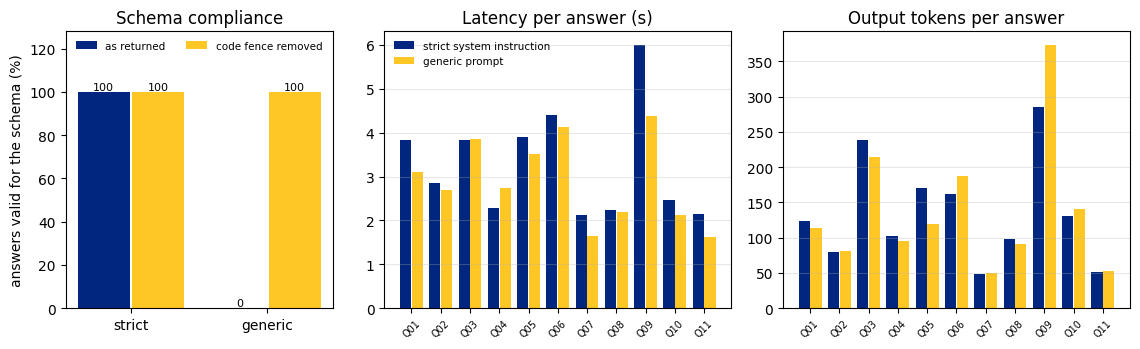

In [22]:
INK, BLUE, GOLD, STEEL, BRICK = "#14213D", "#00267F", "#FFC726", "#6B7A8F", "#B5451B"
per_arm = arms.melt(id_vars=["qid", "arm"], value_vars=["seconds", "tokens_out"], var_name="metric", value_name="amount")
fig, axes = plt.subplots(1, 3, figsize=(11.5, 3.6), gridspec_kw={"width_ratios": [1, 1.3, 1.3]})
for shift, column, colour, tag in ((-.2, "schema_compliant", BLUE, "as returned"), (.2, "valid_after_unfencing", GOLD, "code fence removed")):
    axes[0].bar_label(axes[0].bar(np.arange(2) + shift, contest[column] * 100, width=.38, color=colour, label=tag), fmt="%.0f", fontsize=8)
axes[0].set(xticks=range(2), xticklabels=["strict", "generic"], ylim=(0, 128), ylabel="answers valid for the schema (%)", title="Schema compliance")
axes[0].legend(frameon=False, fontsize=7.5, loc="upper center", ncol=2)
for axis, metric, title in zip(axes[1:], ("seconds", "tokens_out"), ("Latency per answer (s)", "Output tokens per answer")):
    part = per_arm[per_arm.metric == metric]
    for offset, (arm, data) in zip((-.2, .2), part.groupby("arm", sort=False)):
        axis.bar(np.arange(len(data)) + offset, data.amount, width=.38, color=BLUE if arm.startswith("strict") else GOLD, label=arm)
    axis.set(xticks=range(11), xticklabels=[q[0] for q in QUESTION_LIST], title=title)
    axis.tick_params(axis="x", labelsize=7, rotation=45)
    axis.grid(axis="y", alpha=.3)
axes[1].legend(frameon=False, fontsize=7.5)
fig.tight_layout()
fig.savefig(Path(OPTIONS.paths.out, "extension.png"), dpi=300, facecolor="white")
plt.show()

**21. Dashboard.** Indicators, trends, a credit and asset-quality scatter, themes, and the model checks on one page. *Saved as `results/dashboard.png`.*

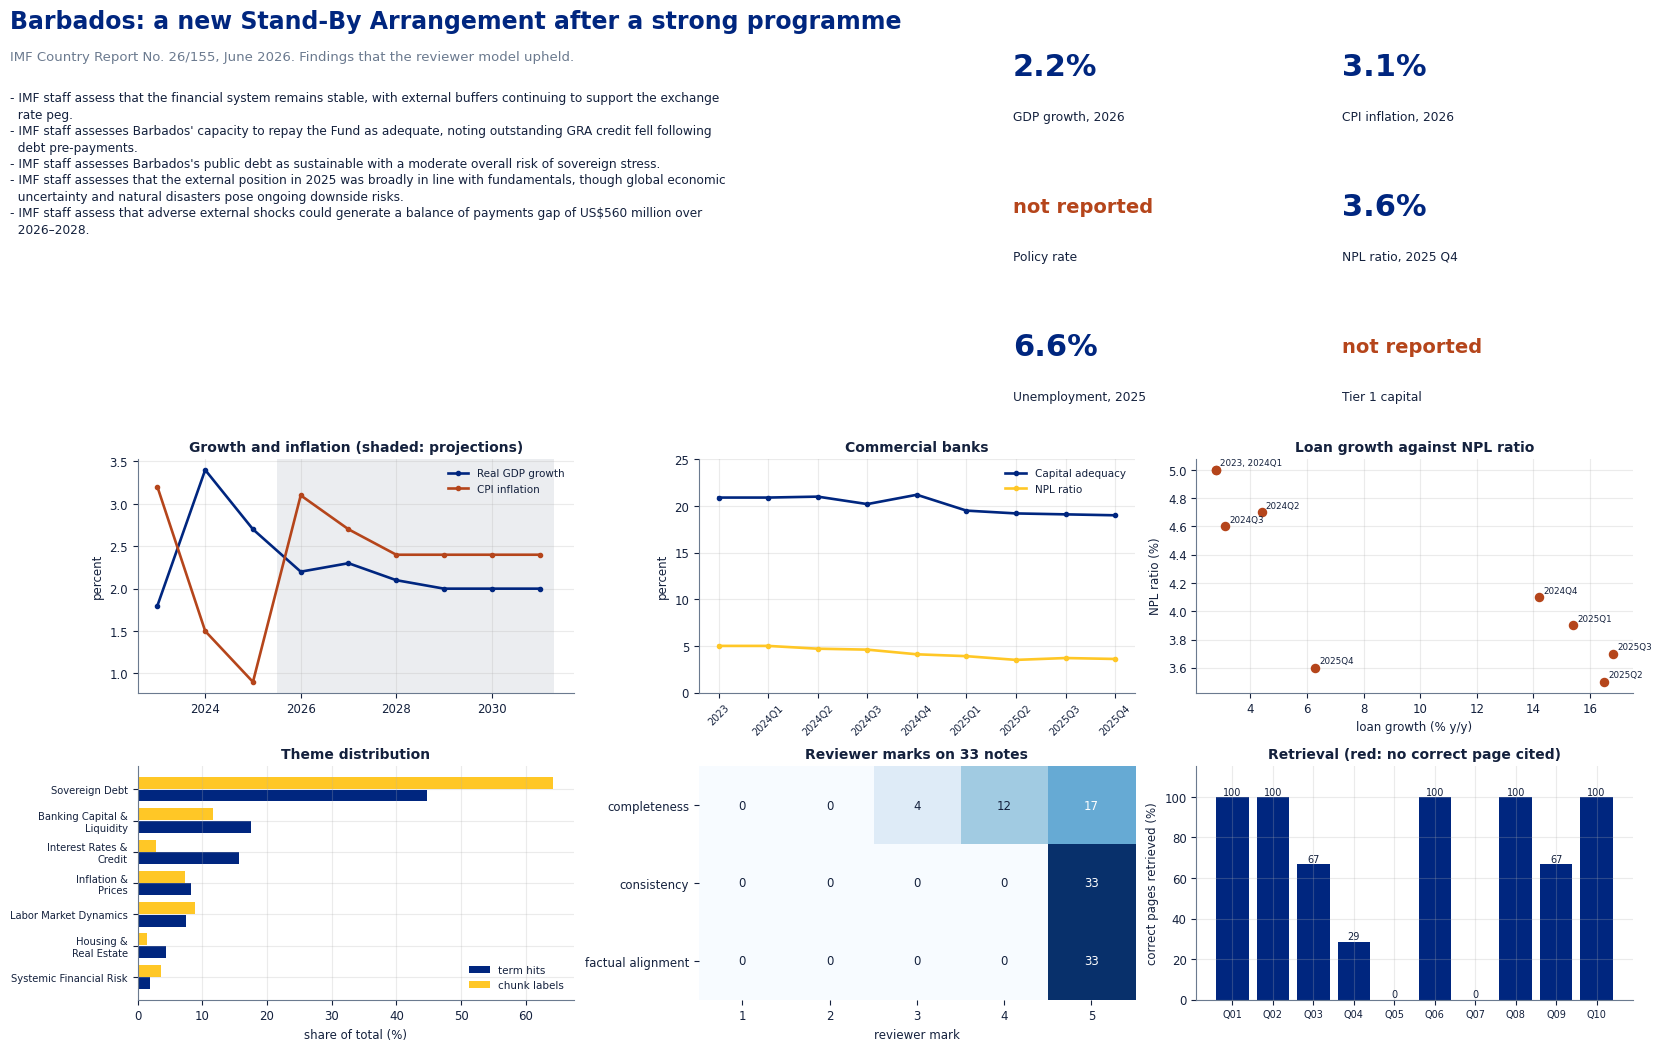

In [23]:
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 8.5, "axes.titlesize": 10, "axes.titleweight": "bold", "axes.spines.top": False, "axes.spines.right": False, "text.color": INK, "axes.labelcolor": INK, "xtick.color": INK, "ytick.color": INK, "axes.edgecolor": STEEL})
row_like = lambda frame, pattern: next(i for i in frame.index if re.search(pattern, i, re.I))
macro_names = {row_like(medium_term, r"Real GDP"): "Real GDP growth", row_like(medium_term, r"CPI inflation \(average\)"): "CPI inflation"}
year_cols = [c for c in medium_term.columns]
macro_long = medium_term.loc[list(macro_names), year_cols].rename(index=macro_names).rename_axis("series").reset_index().melt(id_vars="series", var_name="year", value_name="percent").dropna().astype({"year": int, "percent": float})
quarterly = pd.DataFrame({"Capital adequacy": picture_row("Capital Adequacy Ratio"), "NPL ratio": picture_row("Non-performing loans ratio"), "Loan growth": picture_row("Loans and advances")}).rename_axis("quarter").reset_index()
quarterly_long = pd.melt(quarterly, id_vars="quarter", value_vars=["Capital adequacy", "NPL ratio"], var_name="series", value_name="percent")
fig = plt.figure(figsize=(16.5, 10.4), facecolor="white", layout="constrained")
upper, lower = fig.subfigures(2, 1, height_ratios=[1, 1.45])
text_side, tile_side = upper.subfigures(1, 2, width_ratios=[1.45, 1])
upper_ax = text_side.add_subplot()
upper_ax.axis("off")
upper_ax.text(0, 1.0, "Barbados: a new Stand-By Arrangement after a strong programme", fontsize=17, fontweight="bold", color=BLUE, va="top", transform=upper_ax.transAxes)
upper_ax.text(0, .9, "IMF Country Report No. 26/155, June 2026. Findings that the reviewer model upheld.", fontsize=9.5, color=STEEL, va="top", transform=upper_ax.transAxes)
upheld = [f for f, r in zip(briefing["findings"], briefing["rulings"]) if r["holds"]][:5]
upper_ax.text(0, .8, "\n".join("\n".join(textwrap.wrap(f["sentence"], 118, initial_indent="- ", subsequent_indent="  ")) for f in upheld), fontsize=8.7, va="top", linespacing=1.34, transform=upper_ax.transAxes)
tile_ax = tile_side.add_subplot()
tile_ax.axis("off")
NICE = {"gdp_growth_forecast_pct": "GDP growth", "headline_inflation_rate_pct": "CPI inflation", "central_bank_policy_rate_pct": "Policy rate", "non_performing_loan_ratio": "NPL ratio", "unemployment_rate_pct": "Unemployment", "tier_1_capital_ratio": "Tier 1 capital"}
for spot, (name, nice) in enumerate(NICE.items()):
    col, row, value = spot % 2, spot // 2, target[name]
    x, y = .03 + col * .5, .86 - row * .34
    tile_ax.text(x, y, "not reported" if value is None else f"{value:.1f}%", fontsize=14 if value is None else 22, fontweight="bold", color=BRICK if value is None else BLUE, transform=tile_ax.transAxes, va="center")
    period = ledger.set_index("field").period[name]
    tile_ax.text(x, y - .12, nice if value is None else f"{nice}, {period}", fontsize=8.8, transform=tile_ax.transAxes, va="center")
panels = lower.subplots(2, 3)
for name, part in macro_long.groupby("series", sort=False):
    panels[0, 0].plot(part.year, part.percent, marker="o", ms=3, lw=1.9, color=BLUE if "GDP" in name else BRICK, label=name)
panels[0, 0].axvspan(OPTIONS.source.projection_year - .5, macro_long.year.max() + .3, color=STEEL, alpha=.13, lw=0)
panels[0, 0].set(title="Growth and inflation (shaded: projections)", ylabel="percent")
panels[0, 0].legend(frameon=False, fontsize=7.5)
for name, part in quarterly_long.groupby("series", sort=False):
    panels[0, 1].plot(part.quarter, part.percent, marker="o", ms=3, lw=1.9, color=GOLD if "NPL" in name else BLUE, label=name)
panels[0, 1].set(title="Commercial banks", ylabel="percent", ylim=(0, 25))
panels[0, 1].tick_params(axis="x", labelsize=7, rotation=45)
panels[0, 1].legend(frameon=False, fontsize=7.5)
panels[0, 2].scatter(quarterly["Loan growth"], quarterly["NPL ratio"], color=BRICK, s=34, zorder=3)
for (growth, npl), same in quarterly.groupby(["Loan growth", "NPL ratio"], sort=False):   # quarters with identical values share one label
    panels[0, 2].annotate(", ".join(same.quarter), (growth, npl), fontsize=6.3, xytext=(3, 3), textcoords="offset points")
panels[0, 2].set(title="Loan growth against NPL ratio", xlabel="loan growth (% y/y)", ylabel="NPL ratio (%)")
theme_view = theme_result["table"].sort_values("term_pct").melt(id_vars="theme", value_vars=["term_pct", "label_pct"], var_name="how", value_name="share")
ranked = theme_result["table"].sort_values("term_pct").theme.tolist()
for shift, how, colour, tag in ((-.2, "term_pct", BLUE, "term hits"), (.2, "label_pct", GOLD, "chunk labels")):
    panels[1, 0].barh(np.arange(7) + shift, theme_view[theme_view.how == how].set_index("theme").loc[ranked].share, height=.38, color=colour, label=tag)
panels[1, 0].set(yticks=range(7), yticklabels=[t.replace(" & ", " &\n") for t in ranked], xlabel="share of total (%)", title="Theme distribution")
panels[1, 0].tick_params(axis="y", labelsize=7.2)
panels[1, 0].legend(frameon=False, fontsize=7.5)
grade_long = notes.melt(id_vars="sid", value_vars=["consistency", "completeness", "factual_alignment"], var_name="scale", value_name="mark")
counts = grade_long.groupby(["scale", "mark"]).size().unstack(fill_value=0).reindex(columns=range(1, 6), fill_value=0)
panels[1, 1].imshow(counts.to_numpy(), cmap="Blues", aspect="auto")
panels[1, 1].set(xticks=range(5), xticklabels=range(1, 6), yticks=range(3), yticklabels=[s.replace("_", " ") for s in counts.index], xlabel="reviewer mark", title=f"Reviewer marks on {len(notes)} notes")
for (r, c), n in np.ndenumerate(counts.to_numpy()):
    panels[1, 1].text(c, r, str(n), ha="center", va="center", color="white" if n > counts.to_numpy().max() / 2 else INK)
panels[1, 1].spines[:].set_visible(False)
found = answers.dropna(subset="gold_recall")
panels[1, 2].bar_label(panels[1, 2].bar(found.qid, found.gold_recall * 100, color=[BLUE if c else BRICK for c in found.cited_gold]), fmt="%.0f", fontsize=7)
panels[1, 2].set(ylim=(0, 115), ylabel="correct pages retrieved (%)", title="Retrieval (red: no correct page cited)")
panels[1, 2].tick_params(axis="x", labelsize=7)
for axis in (panels[0, 0], panels[0, 1], panels[0, 2], panels[1, 0], panels[1, 2]):
    axis.grid(alpha=.25)
fig.savefig(Path(OPTIONS.paths.out, "dashboard.png"), dpi=300, facecolor="white")
plt.show()

**22. Run record.** Every request, the prompts and the results journal. *Saved as `results/call_log.json`, `results/prompt_book.json` and `results/journal.json`.*

In [24]:
requests = pd.DataFrame(USAGE)
publish("call_log", {"drafter": OPTIONS.models.drafter, "reviewer": OPTIONS.models.reviewer, "requests": len(requests), "live": int((requests.way == "live").sum()), "from_shelf": int((requests.way == "shelf").sum()), "retries": int(requests.label.str.contains("~").sum()), "rows": requests})
publish("prompt_book", {job.name: {"system": job.value[0], "message": job.value[1]} for job in Ask})
publish("journal", pd.DataFrame(JOURNAL))
import sys, torch, sentence_transformers
print("python", sys.version.split()[0], "| torch", torch.__version__, "| sentence-transformers", sentence_transformers.__version__, "|", subprocess.run(["pdftotext", "-v"], capture_output=True, text=True).stderr.split("\n")[0])
print(f"{len(requests)} requests: {int((requests.way == 'live').sum())} live, {int((requests.way == 'shelf').sum())} from the shelf")
requests.groupby("model").agg(requests=("label", "size"), seconds=("seconds", "mean"), tokens_in=("in", "sum"), tokens_out=("out", "sum")).round(2)

python 3.13.18 | torch 2.14.1+cpu | sentence-transformers 5.7.0 | pdftotext version 24.02.0
166 requests: 0 live, 166 from the shelf


,requests,seconds,tokens_in,tokens_out
model,,,,
gemini-3.5-flash,94,13.66,299607,98614
gemini-3.6-flash,72,4.74,272003,6320
